# RGB Camera Exploration

This notebook explores the world-camera RGB videos.

Core checks:
- video naming and participant/task distribution
- resolution, FPS, frame count, duration, codec
- calibration-task filtering
- sample frames from a selected recording
- brightness, blur/sharpness, and rough motion statistics

In [1]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

DATASET_ROOT = Path("/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18")
VIDEO_ROOT = DATASET_ROOT / "world_camera_videos"

SKIP_TASKS = {"Eye1", "Eye2", "Recalibration1"}

PARTICIPANT_ID = "IA_4_H_02"
TASK_NAME = "Tasche_packen1"

selected_video_path = VIDEO_ROOT / PARTICIPANT_ID / f"{PARTICIPANT_ID}_{TASK_NAME}_world_camera.mp4"
selected_video_path

PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_02/IA_4_H_02_Tasche_packen1_world_camera.mp4')

## Helper Functions

In [2]:
def parse_world_camera_name(path):
    path = Path(path)
    stem = path.stem
    if stem.endswith("_world_camera"):
        stem = stem[: -len("_world_camera")]

    participant_id = path.parent.name
    prefix = f"{participant_id}_"
    task_name = stem[len(prefix):] if stem.startswith(prefix) else stem

    return participant_id, task_name, stem


def fourcc_to_str(value):
    value = int(value)
    chars = [chr((value >> 8 * i) & 0xFF) for i in range(4)]
    return "".join(chars).strip()


def video_metadata(path):
    path = Path(path)
    participant_id, task_name, video_key = parse_world_camera_name(path)
    cap = cv2.VideoCapture(str(path))
    opened = cap.isOpened()

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if opened else 0
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if opened else 0
    fps = float(cap.get(cv2.CAP_PROP_FPS)) if opened else np.nan
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if opened else 0
    fourcc = fourcc_to_str(cap.get(cv2.CAP_PROP_FOURCC)) if opened else ""
    duration_s = frame_count / fps if opened and fps > 0 else np.nan
    cap.release()

    return {
        "participant_id": participant_id,
        "task_name": task_name,
        "video_key": video_key,
        "is_calibration": task_name in SKIP_TASKS,
        "opened": opened,
        "width": width,
        "height": height,
        "fps": fps,
        "frame_count": frame_count,
        "duration_s": duration_s,
        "fourcc": fourcc,
        "path": path,
    }


def read_frame(path, frame_idx):
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        return None
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


def frame_quality_metrics(frame_rgb):
    gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
    brightness_mean = float(gray.mean())
    brightness_std = float(gray.std())
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    return brightness_mean, brightness_std, lap_var

## Dataset-Level Video Metadata

In [3]:
video_paths = sorted(VIDEO_ROOT.glob("*/*.mp4"))
len(video_paths), video_paths[:3]

(111,
 [PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_02/IA_4_H_02_Brief_schreiben1_world_camera.mp4'),
  PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_02/IA_4_H_02_Brief_schreiben2_world_camera.mp4'),
  PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_02/IA_4_H_02_Chaos_several_Tasks_combine1_world_camera.mp4')])

In [5]:
video_df = pd.DataFrame([video_metadata(path) for path in video_paths])
video_df.head()

,participant_id,task_name,video_key,is_calibration,opened,width,height,fps,frame_count,duration_s,fourcc,path
0,IA_4_H_02,Brief_schreiben1,IA_4_H_02_Brief_schreiben1,False,True,1600,1200,30.0,1962,65.400000,FMP4,/home/julius/datasets/seminar_object_detection...
1,IA_4_H_02,Brief_schreiben2,IA_4_H_02_Brief_schreiben2,False,True,1600,1200,30.0,1774,59.133333,FMP4,/home/julius/datasets/seminar_object_detection...
2,IA_4_H_02,Chaos_several_Tasks_combine1,IA_4_H_02_Chaos_several_Tasks_combine1,False,True,1600,1200,30.0,2715,90.500000,FMP4,/home/julius/datasets/seminar_object_detection...
3,IA_4_H_02,Chaos_several_Tasks_combine2,IA_4_H_02_Chaos_several_Tasks_combine2,False,True,1600,1200,30.0,2237,74.566667,FMP4,/home/julius/datasets/seminar_object_detection...
4,IA_4_H_02,Chaos_several_Tasks_combine3,IA_4_H_02_Chaos_several_Tasks_combine3,False,True,1600,1200,30.0,2274,75.800000,FMP4,/home/julius/datasets/seminar_object_detection...


In [6]:
summary = {
    "video_count": len(video_df),
    "opened_count": int(video_df["opened"].sum()),
    "participant_count": video_df["participant_id"].nunique(),
    "calibration_count": int(video_df["is_calibration"].sum()),
    "adl_count": int((~video_df["is_calibration"]).sum()),
}
summary

{'video_count': 111,
 'opened_count': 111,
 'participant_count': 9,
 'calibration_count': 21,
 'adl_count': 90}

In [7]:
video_df[["participant_id", "task_name", "width", "height", "fps", "frame_count", "duration_s", "fourcc", "is_calibration"]].sort_values(["participant_id", "task_name"])

,participant_id,task_name,width,height,fps,frame_count,duration_s,fourcc,is_calibration
0,IA_4_H_02,Brief_schreiben1,1600,1200,30.0,1962,65.400000,FMP4,False
1,IA_4_H_02,Brief_schreiben2,1600,1200,30.0,1774,59.133333,FMP4,False
2,IA_4_H_02,Chaos_several_Tasks_combine1,1600,1200,30.0,2715,90.500000,FMP4,False
3,IA_4_H_02,Chaos_several_Tasks_combine2,1600,1200,30.0,2237,74.566667,FMP4,False
4,IA_4_H_02,Chaos_several_Tasks_combine3,1600,1200,30.0,2274,75.800000,FMP4,False
...,...,...,...,...,...,...,...,...,...
106,IA_4_H_14,Recalibration1,1600,1200,30.0,300,10.000000,FMP4,True
107,IA_4_H_14,Tasche_packen1,1600,1200,30.0,1073,35.766667,FMP4,False
108,IA_4_H_14,Tasche_packen2,1600,1200,30.0,849,28.300000,FMP4,False
109,IA_4_H_14,Teekochen1,1600,1200,30.0,1711,57.033333,FMP4,False


## Resolution, FPS, and Duration Checks

In [8]:
video_df.groupby(["width", "height", "fps", "fourcc"], dropna=False).size().reset_index(name="count").sort_values("count", ascending=False)

,width,height,fps,fourcc,count
0,1600,1200,30.0,FMP4,111


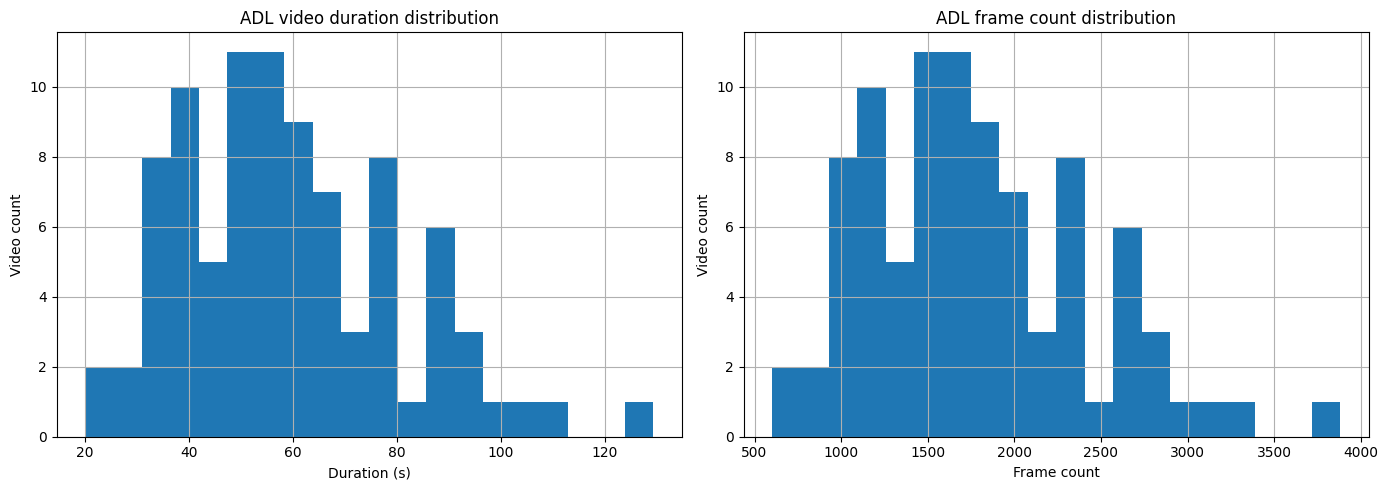

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

adl_df = video_df[~video_df["is_calibration"]].copy()
axes[0].hist(adl_df["duration_s"].dropna(), bins=20)
axes[0].set_xlabel("Duration (s)")
axes[0].set_ylabel("Video count")
axes[0].set_title("ADL video duration distribution")

axes[1].hist(adl_df["frame_count"], bins=20)
axes[1].set_xlabel("Frame count")
axes[1].set_ylabel("Video count")
axes[1].set_title("ADL frame count distribution")

plt.tight_layout()

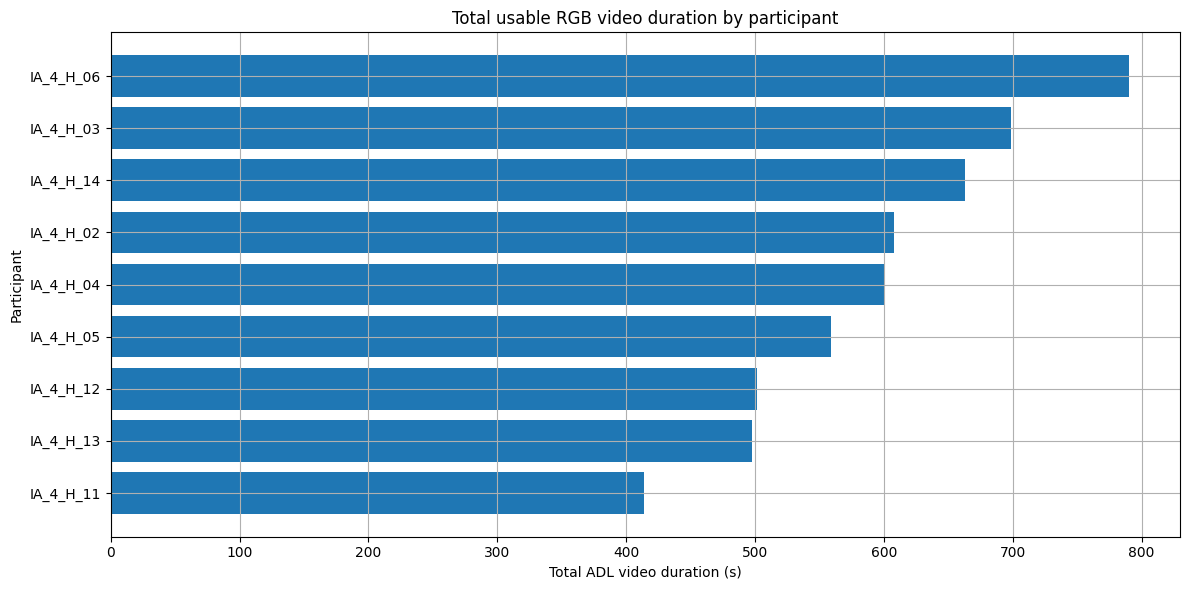

In [10]:
plt.figure(figsize=(12, 6))
participant_duration = adl_df.groupby("participant_id")["duration_s"].sum().sort_values()
plt.barh(participant_duration.index, participant_duration.values)
plt.xlabel("Total ADL video duration (s)")
plt.ylabel("Participant")
plt.title("Total usable RGB video duration by participant")
plt.tight_layout()

## Selected Video

In [11]:
assert selected_video_path.exists(), selected_video_path
selected_meta = video_metadata(selected_video_path)
selected_meta

{'participant_id': 'IA_4_H_02',
 'task_name': 'Tasche_packen1',
 'video_key': 'IA_4_H_02_Tasche_packen1',
 'is_calibration': False,
 'opened': True,
 'width': 1600,
 'height': 1200,
 'fps': 30.0,
 'frame_count': 1039,
 'duration_s': 34.63333333333333,
 'fourcc': 'FMP4',
 'path': PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_02/IA_4_H_02_Tasche_packen1_world_camera.mp4')}

## Sample Frames

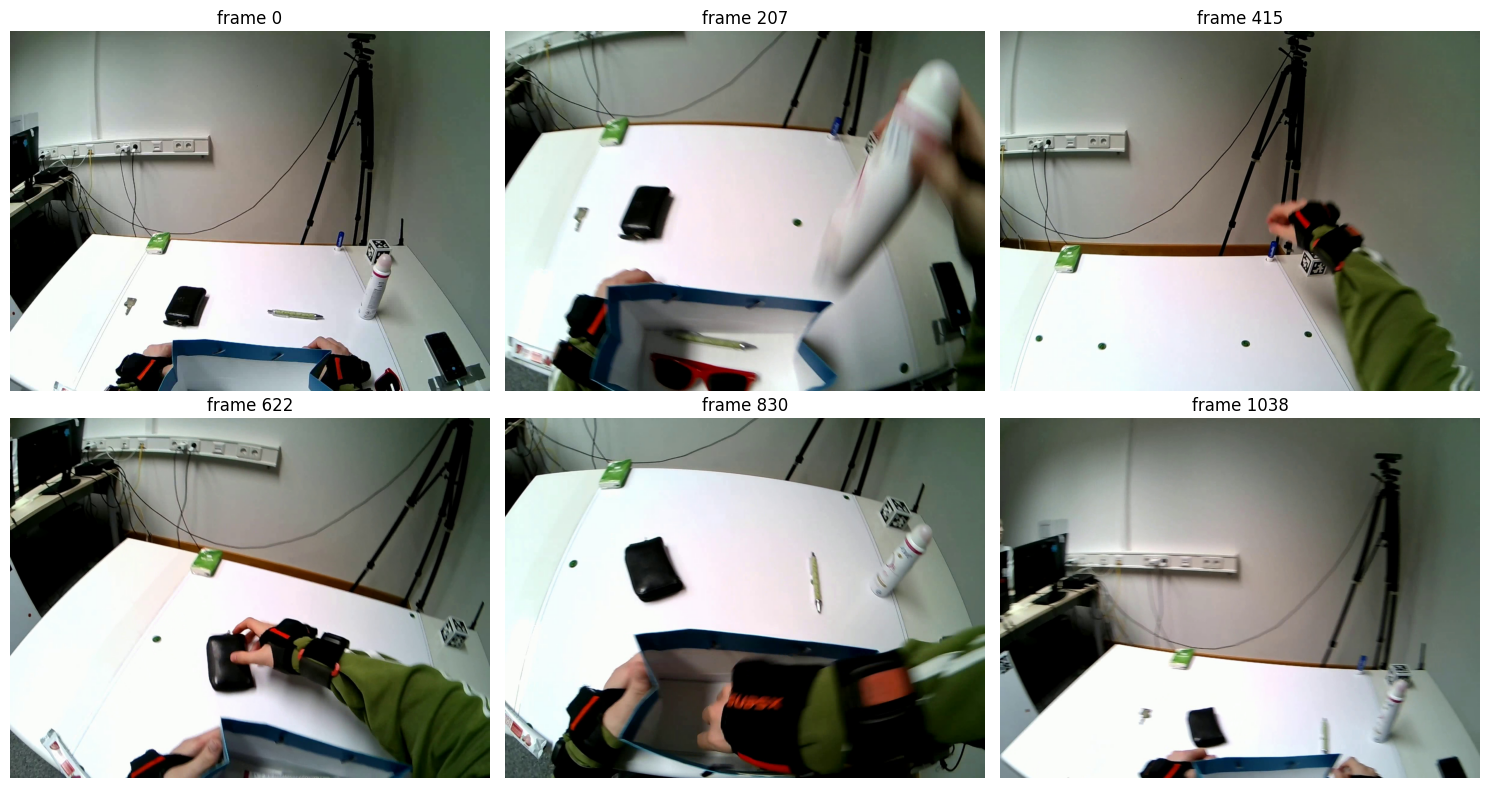

In [12]:
frame_count = selected_meta["frame_count"]
sample_indices = np.linspace(0, max(frame_count - 1, 0), 6, dtype=int)
frames = [read_frame(selected_video_path, idx) for idx in sample_indices]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, idx, frame in zip(axes.ravel(), sample_indices, frames):
    if frame is not None:
        ax.imshow(frame)
    ax.set_title(f"frame {idx}")
    ax.axis("off")
plt.tight_layout()

## Brightness and Sharpness Sampling

`laplacian_var` is a rough sharpness / blur indicator. Lower values usually mean blurrier frames.

In [13]:
quality_indices = np.linspace(0, max(frame_count - 1, 0), min(80, frame_count), dtype=int)
quality_rows = []

for idx in quality_indices:
    frame = read_frame(selected_video_path, idx)
    if frame is None:
        continue
    brightness_mean, brightness_std, laplacian_var = frame_quality_metrics(frame)
    quality_rows.append({
        "frame_idx": int(idx),
        "time_s": idx / selected_meta["fps"] if selected_meta["fps"] else np.nan,
        "brightness_mean": brightness_mean,
        "brightness_std": brightness_std,
        "laplacian_var": laplacian_var,
    })

quality_df = pd.DataFrame(quality_rows)
quality_df.describe()

,frame_idx,time_s,brightness_mean,brightness_std,laplacian_var
count,80.00000,80.000000,80.000000,80.000000,80.000000
mean,518.51250,17.283750,131.147233,79.062826,57.768286
std,305.32278,10.177426,10.680143,8.543308,33.665169
min,0.00000,0.000000,90.011439,61.185002,8.181999
25%,258.75000,8.625000,125.007196,72.370619,30.738502
50%,518.50000,17.283333,131.559822,80.042256,49.873420
75%,778.25000,25.941667,136.934510,86.892998,81.717146
max,1038.00000,34.600000,164.398489,93.387133,150.899569


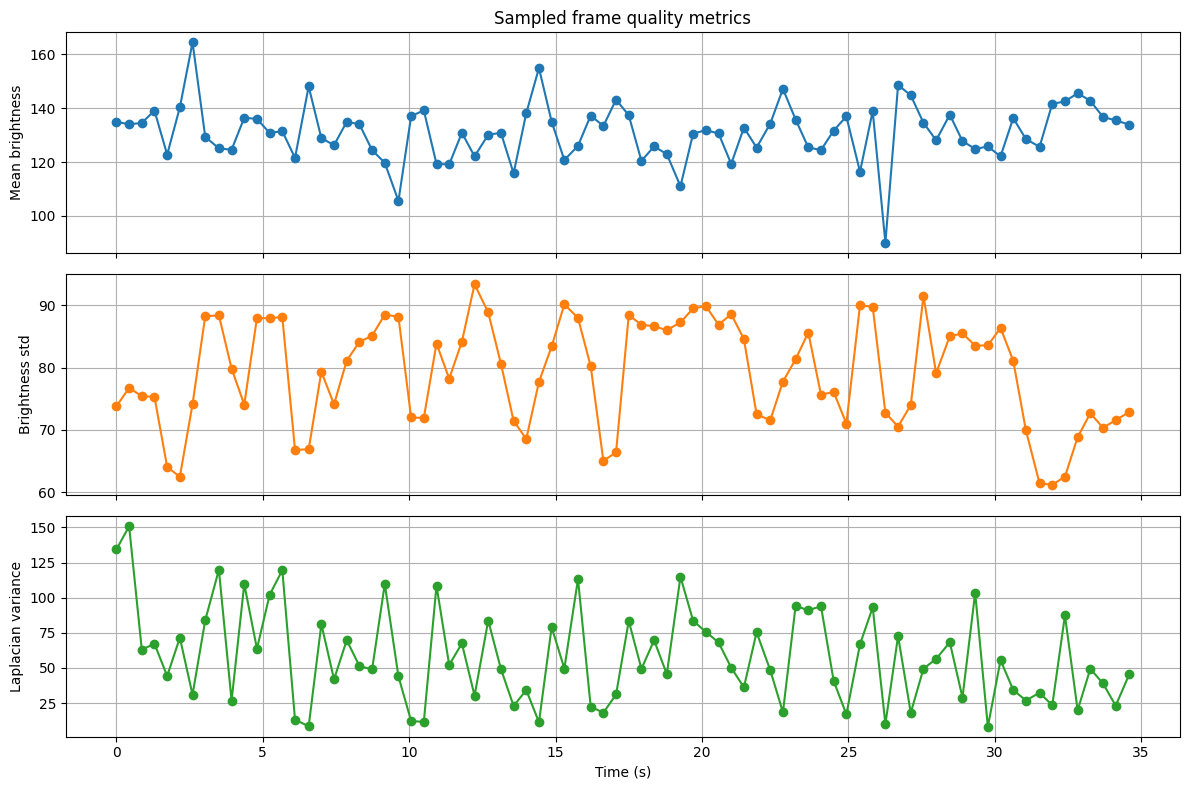

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(quality_df["time_s"], quality_df["brightness_mean"], marker="o")
axes[0].set_ylabel("Mean brightness")
axes[0].set_title("Sampled frame quality metrics")

axes[1].plot(quality_df["time_s"], quality_df["brightness_std"], marker="o", color="tab:orange")
axes[1].set_ylabel("Brightness std")

axes[2].plot(quality_df["time_s"], quality_df["laplacian_var"], marker="o", color="tab:green")
axes[2].set_ylabel("Laplacian variance")
axes[2].set_xlabel("Time (s)")

plt.tight_layout()

## Rough Motion Sampling

This computes mean absolute grayscale difference between sampled neighboring frames. It is not optical flow, but it quickly shows where large visual changes happen.

In [15]:
motion_step = max(int(selected_meta["fps"] // 2), 1)
motion_indices = np.arange(0, max(frame_count - motion_step, 0), max(motion_step, 1))
motion_rows = []

for idx in motion_indices[:200]:
    frame_a = read_frame(selected_video_path, int(idx))
    frame_b = read_frame(selected_video_path, int(idx + motion_step))
    if frame_a is None or frame_b is None:
        continue
    gray_a = cv2.cvtColor(frame_a, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gray_b = cv2.cvtColor(frame_b, cv2.COLOR_RGB2GRAY).astype(np.float32)
    diff = np.mean(np.abs(gray_b - gray_a))
    motion_rows.append({
        "frame_idx": int(idx),
        "time_s": idx / selected_meta["fps"] if selected_meta["fps"] else np.nan,
        "mean_abs_frame_diff": float(diff),
    })

motion_df = pd.DataFrame(motion_rows)
motion_df.describe()

,frame_idx,time_s,mean_abs_frame_diff
count,69.00000,69.000000,69.000000
mean,510.00000,17.000000,54.887997
std,300.93604,10.031201,18.290058
min,0.00000,0.000000,17.786400
25%,255.00000,8.500000,43.493088
50%,510.00000,17.000000,55.025337
75%,765.00000,25.500000,65.973091
max,1020.00000,34.000000,107.126076


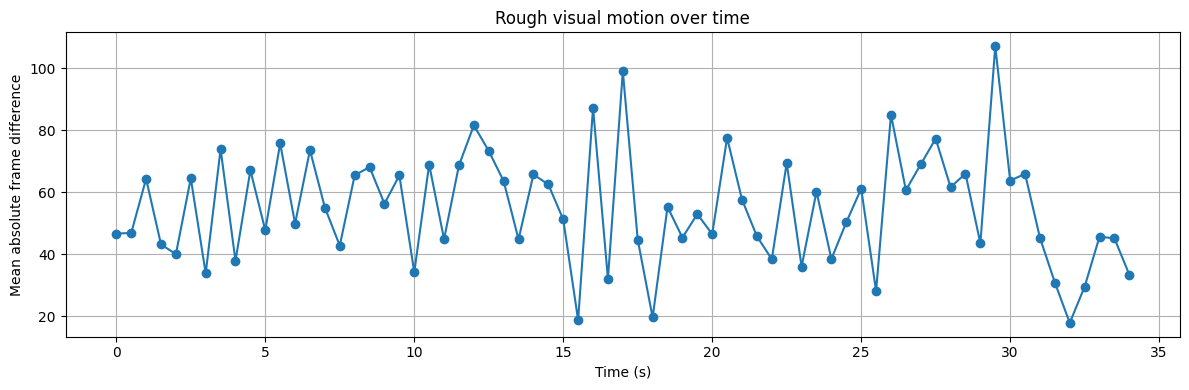

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(motion_df["time_s"], motion_df["mean_abs_frame_diff"], marker="o")
plt.xlabel("Time (s)")
plt.ylabel("Mean absolute frame difference")
plt.title("Rough visual motion over time")
plt.tight_layout()

## Recommended Outputs for RGB Exploration

For this project, the most useful RGB-camera exploration results are:

- resolution and FPS consistency across all videos
- frame count and duration per task
- calibration vs usable ADL video count
- sample frames for quick visual sanity checks
- brightness and sharpness distributions to catch bad recordings
- rough motion statistics to identify static or unusual segments
- coordinate-system reference for YOLO bbox output, especially before comparing with gaze and skeleton hand keypoints